### Customer Churn Prediction
**Goal:** Predict which telecom customers will leave (churn), identify the main reasons, and recommend strategies to reduce churn.

**Dataset:** Telco Customer Churn (Kaggle/IBM): 7,043 customers, 21 columns. Target: Churn (Yes/No).

**Approach**
1. Clean data and explore churn patterns
2. Train Logistic Regression and Random Forest
3. Use feature selection to test whether fewer features perform just as well
4. Evaluate with recall, precision, F1 and ROC-AUC against a baseline
5. Translate results into business recommendations

In [132]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             recall_score, precision_score, f1_score,
                             roc_auc_score, RocCurveDisplay, precision_recall_curve)

In [133]:
# Data Loading and Preprocessing

customers = pd.read_csv('Telco-Customer-Churn.csv')

# Check types of columns
print(customers.info()) # Total Charges wrong type, needs change
customers.head()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [134]:
print(f" Missing values: {customers.isnull().sum().sum()}")
print(f" Duplicated rows: {customers.duplicated().sum()}")

 Missing values: 0
 Duplicated rows: 0


In [135]:
# Set customerID as index, not a feature for prediction
customers = customers.set_index('customerID')  

In [136]:
 # Convert TotalCharges to numeric
customers['TotalCharges'] = pd.to_numeric(customers['TotalCharges'], errors='coerce') 

# Checking whether NaN TotalCharges are associated with 0 tenure
missing = customers["TotalCharges"].isna()
customers.loc[missing, ["tenure", "MonthlyCharges", "TotalCharges"]]


,tenure,MonthlyCharges,TotalCharges
customerID,,,
4472-LVYGI,0,52.55,NaN
3115-CZMZD,0,20.25,NaN
5709-LVOEQ,0,80.85,NaN
4367-NUYAO,0,25.75,NaN
1371-DWPAZ,0,56.05,NaN
7644-OMVMY,0,19.85,NaN
3213-VVOLG,0,25.35,NaN
2520-SGTTA,0,20.00,NaN
2923-ARZLG,0,19.70,NaN


In [137]:
# Replacing NaN TotalCharges with 0, since  associated with 0 tenure
customers.loc[missing, "TotalCharges"] = 0

In [138]:
# Print the categories for text columns with more than 2 options
for col in customers.select_dtypes(include="str").columns:
    if customers[col].nunique() > 2:
        print(col, customers[col].unique())

MultipleLines <ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService <ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup <ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Contract <ArrowStringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str
PaymentMethod <ArrowStringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str


Categories are clean, with no typos. We are keeping “No internet service” and “No phone service” as separate categories to preserve the difference between declining a service and not having internet or phone at all.

In [139]:
# Convert Churn (target) column to 1/0 for modeling
customers['Churn'] = customers['Churn'].map({'No': 0, 'Yes': 1})
print(f"Churn rate {customers['Churn'].mean():.2%}")

Churn rate 26.54%


About 26% of customers churn, so most customers stay. Accuracy can be misleading here, so we focus on recall (catching customers who leave).

### Exploratory Analysis
Looking at:
- Does contract type affect customers likeliness of leaving?
- Do customers with shorter tenure (# months the customer been with  company) churn more often?
- Are higher monthly charges linked to more churn?
- Does having tech support reduce churn?

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64


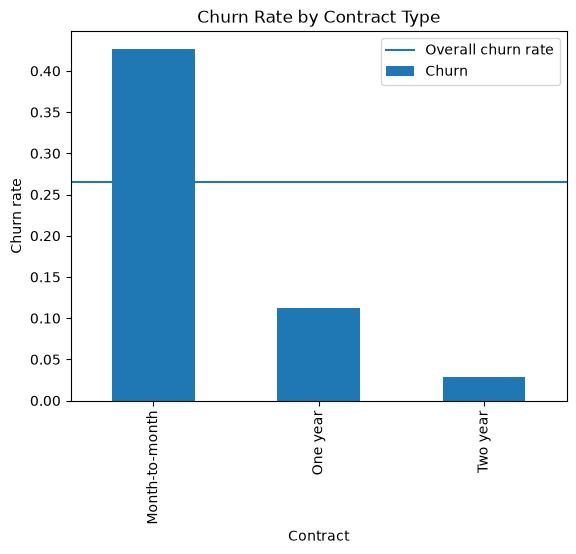

In [147]:
# Churn rate by contract type
churn_by_contract = customers.groupby('Contract')['Churn'].mean()
print(churn_by_contract)

# Plotting churn rate by contract type
churn_by_contract.plot(kind="bar")
plt.axhline(customers["Churn"].mean(), label="Overall churn rate")
plt.ylabel("Churn rate")
plt.title("Churn Rate by Contract Type")
plt.legend()
plt.show()

Month-to-month customers churn at 43%, well above the 26.5% average, while one-year (11%) and two-year (3%) customers churn far less. Month-to-month customers pull the overall churn rate up, which suggests that moving customers onto longer contracts could reduce churn.

tenure
0-12 mo     0.474382
13-24 mo    0.287109
25-36 mo    0.216346
37-48 mo    0.190289
49-60 mo    0.144231
61-72 mo    0.066098
Name: Churn, dtype: float64


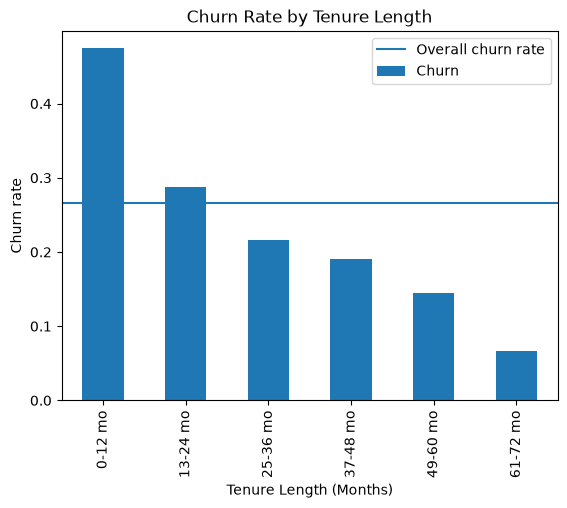

In [ ]:
# Churn rate by tenuure length

# Create tenure categories by length
edges = np.linspace(0, 72, 7)  
labels = ["0-12 mo", "13-24 mo", "25-36 mo", "37-48 mo", "49-60 mo", "61-72 mo"] 
tenure_year = pd.cut(customers["tenure"], bins=edges, labels=labels, include_lowest=True)
tenure_churn = customers.groupby(tenure_year)["Churn"].mean()
print(tenure_churn)

# Plotting churn rate by tenure length
tenure_churn.plot(kind="bar")
plt.axhline(customers["Churn"].mean(), label="Overall churn rate")
plt.xlabel("Tenure Length (Months)")
plt.ylabel("Churn rate")
plt.title("Churn Rate by Tenure Length")
plt.legend()
plt.show()

Churn drops steadily the longer customers stay. First-year customers churn at 47%, almost half, and year 2 is still slightly above average at 29%. After 2 years, churn falls below average and keeps dropping. This suggests retention efforts should focus on new customers, especially in their first year.

In [ ]:
# Looking at churn rates by contract length and tenure 
churners = customers[customers["Churn"] == 1]
churner_groups = pd.crosstab(tenure_year[churners.index], churners["Contract"], normalize="all")
print(churner_groups)

Contract  Month-to-month  One year  Two year
tenure                                      
0-12 mo         0.547887  0.006956  0.000000
13-24 mo        0.148743  0.008561  0.000000
25-36 mo        0.084537  0.010701  0.001070
37-48 mo        0.056715  0.018727  0.002140
49-60 mo        0.034778  0.023542  0.005886
61-72 mo        0.012841  0.020332  0.016586


First-year month-to-month customers make up 55% of all churners, more than half of all lost customers. Month-to-month customers overall account for about 89% of churn. This is the key group to target for retention.

Churn
0    61.265124
1    74.441332
Name: MonthlyCharges, dtype: float64


Text(0.5, 1.0, 'Distribution of Monthly Charges by Churn Status')

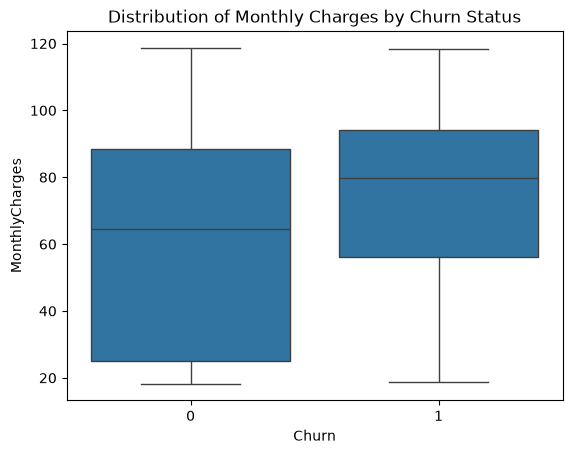

In [174]:
# Do monthly charges have an effect on churn? 

avg_monthly_charges = customers.groupby("Churn")["MonthlyCharges"].mean()
print(avg_monthly_charges)

# Distribution of monthly charges by churn status
sns.boxplot(x="Churn", y="MonthlyCharges", data=customers)
plt.title("Distribution of Monthly Charges by Churn Status")

Customers who churned paid about $\13 more per month on average ($\74 vs. $61). Most churners pay between roughly $\56 and $\94, mostly phone-only customers without internet. Higher charges are associated with churn, but this may be partly due to the type of service (for example, fiber optic internet) rather than price alone, so we check internet service next.

InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: Churn, dtype: float64


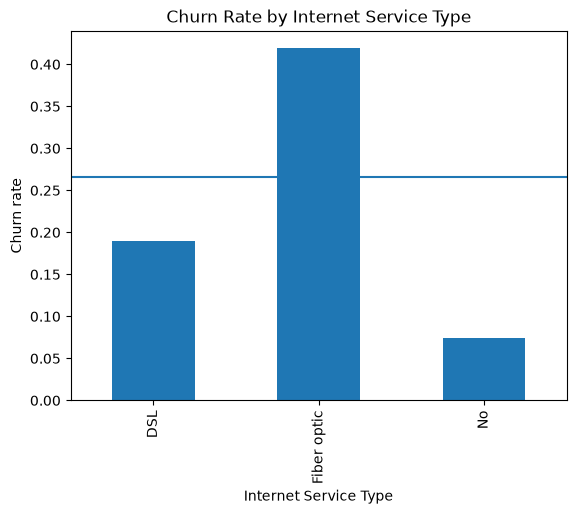

InternetService
DSL            58.102169
Fiber optic    91.500129
No             21.079194
Name: MonthlyCharges, dtype: float64
First-year customers with monthly contracts: 1994
Percent with fiber: 46%
Share of group's churners with fiber: 63%


In [198]:
# Internet service impact on churn rates
internet_churn = customers.groupby("InternetService")["Churn"].mean()
print(internet_churn)

# Plotting churn rates by Internet service type
plot = internet_churn.plot(kind="bar", title="Churn Rate by Internet Service Type")
plt.axhline(customers["Churn"].mean(), label="Overall churn rate")
plt.ylabel("Churn rate")
plt.xlabel("Internet Service Type")
plt.show()

# Monthly charges by internet service type
print(customers.groupby("InternetService")["MonthlyCharges"].mean())

# % of customers with fiber optic and their churn rate, for first-year, month-to-month customers

# High-risk group: first-year, month-to-month customers
group = customers[(customers["tenure"] <= 12) & (customers["Contract"] == "Month-to-month")]
fiber = group[group["InternetService"] == "Fiber optic"]

# % of this group has fiber
print(f"First-year customers with monthly contracts: {len(group)}")
print(f"Percent with fiber: {len(fiber) / len(group):.0%}")

# $ of churners in this group with fiber
group_churners = group[group["Churn"] == 1]
print(f"Share of group's churners with fiber: {(group_churners['InternetService'] == 'Fiber optic').mean():.0%}")


Fiber optic is the most expensive service ($\91.50/month vs. $\58 for DSL). Among first-year month-to-month customers (1,994 people), 46% have fiber, yet fiber customers make up 63% of those who churned. Fiber is strongly associated with churn even within the highest-risk group, and it likely explains part of why churners pay more each month.

TechSupport
No                     0.416355
No internet service    0.074050
Yes                    0.151663
Name: Churn, dtype: float64


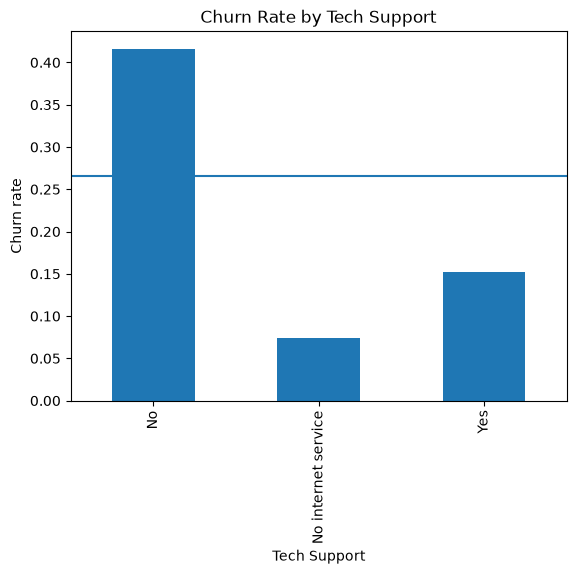

In [189]:
# Tech support groups churn rate 
tech_support_churn = customers.groupby("TechSupport")["Churn"].mean()
print(tech_support_churn)

# Plotting churn rates by tech support group
plot = tech_support_churn.plot(kind="bar", title="Churn Rate by Tech Support")
plt.axhline(customers["Churn"].mean(), label="Overall churn rate")
plt.ylabel("Churn rate")
plt.xlabel("Tech Support")
plt.show() 


Among internet customers, those without tech support churn at 42%, nearly 3× the rate of those with tech support (15%). Customers with no internet service churn the least (7%). This suggests offering tech support could help keep internet customers, though it may overlap with other factors like internet type.

### EDA Summary

The highest-risk segment is **first-year, month-to-month customers**: they churn at 47% and account for 55% of all churned customers. Month-to-month contracts overall drive 89% of churn.

Key factors associated with higher churn:
- **Contract type:** Month-to-month customers churn at 43% vs. 11% (one-year) and 3% (two-year)
- **Tenure:** Churn is highest in year 1 (47%) and drops steadily — after 2 years it falls below the 26.5% average
- **Internet service:** Fiber optic customers churn at 42% and pay ~$\91/month vs. $58 for DSL; fiber customers make up 63% of churners in the highest-risk group despite being only 46% of it
- **Tech support:** Internet customers without tech support churn at 42%, nearly 3× those with it (15%)

These patterns motivate using **recall** as the primary metric (catching churners matters more than avoiding false alarms) and inform which features will carry the most weight in the models.